# Tomography: from the measurement to the segmentation

This notebook follows a tomography experiment step by step and turns every step into a scene of a SciView film:

1. **The sample**: a small sandstone core with pores and grains of a heavy mineral.
2. **The measurement**: 180 neutron radiographs while the sample turns (Beer–Lambert law, counting noise).
3. **The reconstruction**: one sinogram per slice, filtered back-projection.
4. **The segmentation**: three phases from the grey-value histogram, then the pores counted and measured.
5. **The film**: five scenes made from these results, rendered to MP4.

The scan is simulated, so the notebook runs anywhere and every number can be checked against the truth. To use
your own data, load your radiographs in step 2 (or your reconstructed volume in step 3) and keep the rest.

Install: `pip install "sciview[math,science]"` (scikit-image and SciPy do the analysis).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy import ndimage as ndi
from skimage import measure
from skimage.filters import threshold_multiotsu
from skimage.transform import iradon, radon

import sciview as sv
from sciview.jupyter import still

FILM = Path("films/tomography")              # the film's folder: its project file and assets
ASSETS = FILM / "assets"
(ASSETS / "radiographs").mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(7)
print("SciView", sv.__version__)

SciView 1.0.0


## 1. The sample

A cylinder 6.4 mm across (128 voxels of 50 µm), made of quartz, with about 70 pores and 30 grains of a heavy
mineral. Each voxel holds its attenuation coefficient relative to quartz: pores 0, quartz 1, heavy grains 2.6.

true porosity 3.25 %, heavy grains 1.00 %


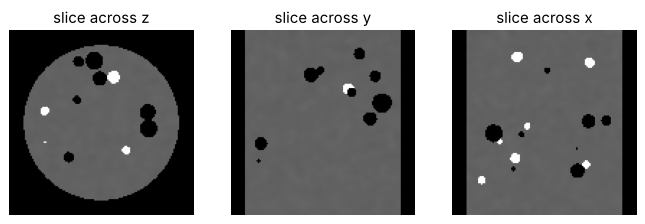

In [2]:
N, VOXEL_UM = 128, 50
z, y, x = np.mgrid[:N, :N, :N].astype(np.float32)
c = (N - 1) / 2
core = np.hypot(x - c, y - c) < 0.42 * N            # the cylinder, standing along z


def spheres(count, r_min, r_max):
    """A mask of random spheres inside the core."""
    mask = np.zeros((N, N, N), bool)
    for _ in range(count):
        a = rng.uniform(0, 2 * np.pi)
        rr = 0.36 * N * np.sqrt(rng.uniform())
        cz, cy, cx = rng.uniform(10, N - 10), c + rr * np.sin(a), c + rr * np.cos(a)
        mask |= (x - cx) ** 2 + (y - cy) ** 2 + (z - cz) ** 2 < rng.uniform(r_min, r_max) ** 2
    return mask & core


pores = spheres(70, 2.5, 7.0)
grains = spheres(60, 2.5, 4.5) & ~pores
texture = ndi.gaussian_filter(rng.normal(0, 1, (N, N, N)).astype(np.float32), 2) * 0.25
truth = np.where(core, 1.0 + texture, 0.0).astype(np.float32)
truth[pores] = 0.0
truth[grains] = 2.6
true_porosity = pores.sum() / core.sum()
print(f"true porosity {100 * true_porosity:.2f} %, heavy grains {100 * grains.sum() / core.sum():.2f} %")

fig, ax = plt.subplots(1, 3)
for a, img, name in zip(ax, (truth[N // 2], truth[:, N // 2], truth[:, :, N // 2]), ("z", "y", "x")):
    a.imshow(img, cmap="gray", origin="lower", vmin=0, vmax=2.6)
    a.set_title(f"slice across {name}")
    a.axis("off")

## 2. The measurement

A parallel neutron beam crosses the sample; the detector records the transmitted intensity
$I = I_0\, e^{-\int \mu\, ds}$. The sample turns about its axis and a radiograph is taken every degree over
180°. Counting noise is Poisson with 3000 counts in the open beam.

**Your data:** load your normalised radiographs (flat- and dark-field corrected) as an array
`transmission[z, detector, angle]` and skip the simulation.

180 radiographs of 128 x 128 pixels; lowest transmission 0.13


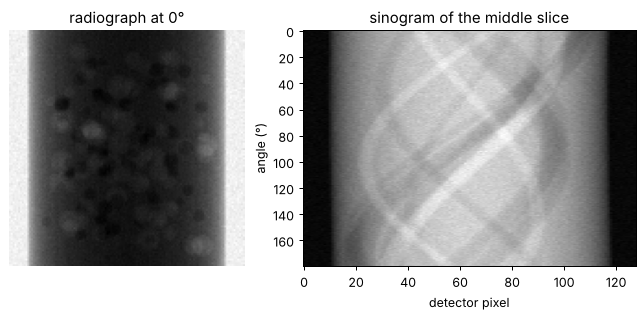

In [3]:
ANGLES = np.arange(180, dtype=float)                # the sample's rotation, degrees
THETA = ANGLES - 90                                  # the same angles in scikit-image's convention
MU_PER_VOXEL = 0.014                                 # quartz: 1.4 % of the beam lost per 50 µm
I0 = 3000

line_integrals = np.stack([radon(s, theta=THETA, circle=True) for s in truth * MU_PER_VOXEL])  # (z, det, angle)
counts = rng.poisson(I0 * np.exp(-line_integrals))
transmission = counts / I0
print(f"{transmission.shape[2]} radiographs of {transmission.shape[0]} x {transmission.shape[1]} pixels; "
      f"lowest transmission {transmission.min():.2f}")

for k in range(len(ANGLES)):                          # the radiographs, as the detector will show them
    img = np.clip(transmission[::-1, ::-1, k], 0, 1.05) / 1.05     # top = top of the sample, as seen from the beam
    Image.fromarray((img * 255).astype(np.uint8)).save(ASSETS / "radiographs" / f"r_{k:03d}.png")

fig, ax = plt.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].imshow(transmission[::-1, :, 0], cmap="gray")
ax[0].set_title("radiograph at 0°")
ax[1].imshow(-np.log(np.maximum(transmission[N // 2], 1 / I0)).T, cmap="gray", aspect="auto")
ax[1].set_title("sinogram of the middle slice")
ax[1].set_xlabel("detector pixel")
ax[1].set_ylabel("angle (°)")
ax[0].axis("off");

## 3. The reconstruction

The logarithm of the transmission gives back the line integrals, one sinogram per slice. Filtered
back-projection with a ramp filter rebuilds each slice; dividing by the attenuation per voxel brings the
values back to the scale of the sample (quartz = 1).

reconstructed (128, 128, 128); error inside the sample 0.13 (quartz = 1)


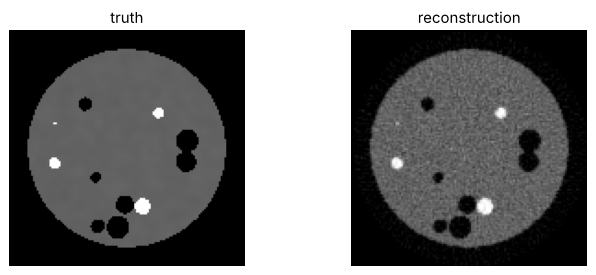

In [4]:
projections = -np.log(np.maximum(transmission, 1 / I0))
rec = np.stack([iradon(p, theta=THETA, filter_name="ramp", circle=True) for p in projections])
rec = (rec / MU_PER_VOXEL).astype(np.float32)
rms = np.sqrt(np.mean((rec - truth)[core] ** 2))
print(f"reconstructed {rec.shape}; error inside the sample {rms:.2f} (quartz = 1)")

fig, ax = plt.subplots(1, 2)
for a, img, name in zip(ax, (truth[N // 2], rec[N // 2]), ("truth", "reconstruction")):
    a.imshow(img, cmap="gray", vmin=0, vmax=2.6)
    a.set_title(name)
    a.axis("off")

## 4. The segmentation

A 3 × 3 × 3 median filter calms the noise. The sample is everything denser than half of quartz, with holes
filled slice by slice. Multi-Otsu thresholds split its grey values into three classes: pores, quartz and
heavy grains. Connected pore voxels are labelled as separate pores and measured.

thresholds 0.55 and 1.66
porosity 3.4 % (true 3.2 %), heavy grains 0.9 %
58 pores, mean diameter 475 µm


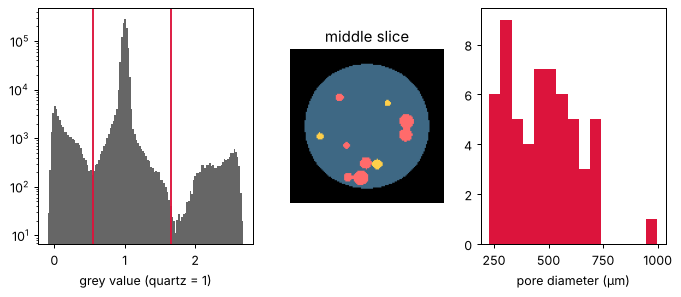

In [5]:
smooth = ndi.median_filter(rec, size=3)
sample = np.stack([ndi.binary_fill_holes(s > 0.5) for s in smooth])
sample = ndi.binary_erosion(sample, iterations=2)
values = smooth[sample]
t_pore, t_grain = threshold_multiotsu(values, classes=3)
phase = np.digitize(smooth, [t_pore, t_grain])        # 0 pore, 1 quartz, 2 heavy grain
pore_mask = (phase == 0) & sample
grain_mask = (phase == 2) & sample
porosity = pore_mask.sum() / sample.sum()
grain_fraction = grain_mask.sum() / sample.sum()

labels = measure.label(pore_mask)
props = [p for p in measure.regionprops(labels) if p.area >= 8]          # ignore specks of noise
diam_um = np.array([p.equivalent_diameter_area for p in props]) * VOXEL_UM
print(f"thresholds {t_pore:.2f} and {t_grain:.2f}")
print(f"porosity {100 * porosity:.1f} % (true {100 * true_porosity:.1f} %), heavy grains {100 * grain_fraction:.1f} %")
print(f"{len(props)} pores, mean diameter {diam_um.mean():.0f} µm")

fig, ax = plt.subplots(1, 3, gridspec_kw={"width_ratios": [1.4, 1, 1.2]})
ax[0].hist(values, bins=120, color="0.4")
for t in (t_pore, t_grain):
    ax[0].axvline(t, color="crimson")
ax[0].set_xlabel("grey value (quartz = 1)")
ax[0].set_yscale("log")
COLORS = np.array([[255, 107, 107], [62, 104, 132], [255, 207, 74]], np.uint8)   # pores, quartz, grains
seg = np.zeros((N, N, 3), np.uint8)
seg[sample[N // 2]] = COLORS[phase[N // 2][sample[N // 2]]]
ax[1].imshow(seg)
ax[1].set_title("middle slice")
ax[1].axis("off")
ax[2].hist(diam_um, bins=15, color="crimson")
ax[2].set_xlabel("pore diameter (µm)");

## 5. The film

Everything the film shows comes from the arrays above, saved into the film's `assets` folder. The project
file is an ordinary SciView film: open it in the editor later (`sciview edit films/tomography/tomography.sciview.json`)
to change colours, timing or words.

In [6]:
def norm(a, lo, hi):
    return np.clip((a - lo) / (hi - lo), 0, 1).astype(np.float32)


np.save(ASSETS / "sample.npy", norm(truth, 0, 2.6))
np.save(ASSETS / "reconstruction.npy", norm(smooth, 0, 2.8))
np.save(ASSETS / "pores.npy", ndi.gaussian_filter(pore_mask.astype(np.float32), 0.8))
np.save(ASSETS / "grains.npy", ndi.gaussian_filter(grain_mask.astype(np.float32), 0.8))
Image.fromarray((norm(truth[N // 2], 0, 2.6) * 255).astype(np.uint8)).save(ASSETS / "slice_true.png")
Image.fromarray((norm(smooth[N // 2], 0, 2.8) * 255).astype(np.uint8)).save(ASSETS / "slice_rec.png")
seg_rgba = np.zeros((N, N, 4), np.uint8)
seg_rgba[..., :3] = seg
seg_rgba[..., 3] = sample[N // 2] * 255
Image.fromarray(seg_rgba).save(ASSETS / "slice_seg.png")
np.savetxt(ASSETS / "grey_values.csv", rng.choice(values, 40000), header="value", comments="", fmt="%.4f")

film = sv.Project(path=FILM / "tomography.sciview.json", title="Inside a sandstone core",
                  author="SciView example", duration=10.0, stars=0.15)
film.palette["pore"] = "#ff6b6b"
film.palette["quartz"] = "#3e6884"


def show(scene, t, scale=0.4):
    """A still of one moment of a scene, in the notebook."""
    return still(film, film.scene_start(scene) + t, scale)

### Scene 1: the measurement

The sample (its true volume, drawn as a maximum-intensity projection) turns in the beam while the detector shows
the radiograph measured at that angle: the detector's image is the folder of radiographs, stepped in time with
the rotation.

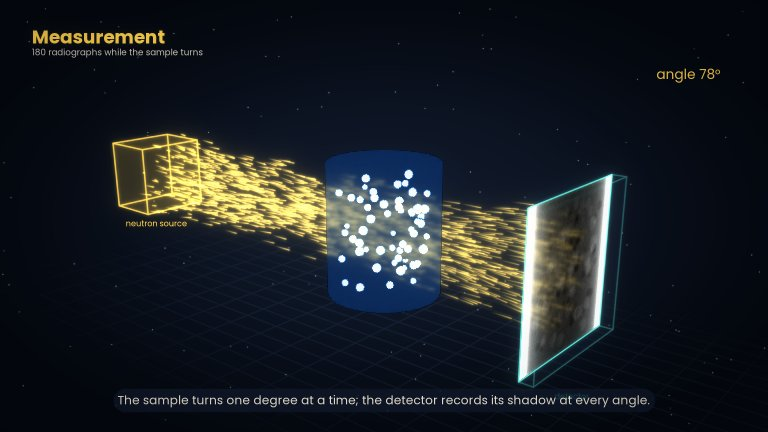

In [7]:
s1 = film.scenes[0]
s1.name = "Measurement"
cam = s1.camera
cam.set("target", (0, 0, 0)).set("fov", 30).set("offset", (0, 30))
cam.key("azimuth", 0, -62).key("azimuth", 10, -38, "in_out")
cam.key("elevation", 0, 20).key("elevation", 10, 14, "in_out")
cam.key("distance", 0, 190).key("distance", 10, 165, "in_out")

film.add("title", text="Measurement", subtitle="180 radiographs while the sample turns", start=0.2)
film.add("grid3d", center=(0, 0, -24), size=(220, 110), divisions=22)
film.add("box", name="Source", center=(-84, 0, 0), size=(14, 18, 18), edge_color="gold", fill_color="gold",
         label="neutron source", label_position="below", label_color="gold", start=0.3)
film.add("beam", name="Neutrons", source=(-76, 0, 0), target=(44, 0, 0), source_radius=12, target_radius=12,
         rate=420, speed=40, streak=5, brightness=0.8, start=0.8)
sample_vol = film.add("volume", name="Sample", data="assets/sample.npy", mode="mip", size=30, colormap="ice",
                      vmin=0, vmax=1, gamma=0.8, clear_below=0.1, samples=96, outline=False, start=0.5)
sample_vol.key("rotation", 1.5, (0, 0, 0), "linear").key("rotation", 9.5, (0, 0, 179), "linear")
det = film.add("screen", name="Detector", center=(46, 0, 0), size=(32, 32), thickness=3,
               image="assets/radiographs/*.png", colormap="gray", image_glow=0.2, label="detector",
               label_color="teal", label_position="below", start=0.6)
det.key("step", 1.5, 0, "linear").key("step", 9.5, 179, "linear")
angle = film.add("text", name="Angle", text="angle {value:.0f}°", position=(1640, 160), size=34, color="gold",
                 start=1.2)
angle.key("value", 1.5, 0, "linear").key("value", 9.5, 179, "linear")
film.add("caption", text="The sample turns one degree at a time; the detector records its shadow at every angle.",
         style="box", start=1.0, end=9.8)
show(s1, 5.0)

### Scene 2: the reconstruction

SciView's sinogram object scans the middle slice projection by projection, and the back-projection object rebuilds
it from the projections recorded so far, with the same ramp filter as step 3.

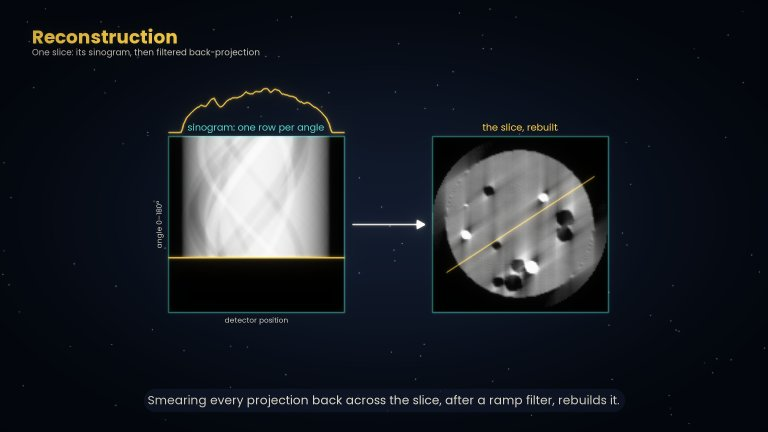

In [8]:
s2 = film.add_scene("Reconstruction", 9.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="Reconstruction", subtitle="One slice: its sinogram, then filtered back-projection",
         start=0.2)
sino = film.add("sinogram", source="image", image="assets/slice_true.png", resolution=128, angles=180,
                position=(640, 560), size=(440, 440), profile=True, start=0.4)
sino.key("progress", 1.0, 0.0, "linear").key("progress", 7.5, 1.0, "linear")
film.add("backprojection", sinogram=sino.id, position=(1300, 560), size=(440, 440), start=0.8)
film.add("text", text="sinogram: one row per angle", position=(640, 300), size=24, color="teal", align="center",
         start=0.6)
film.add("text", text="the slice, rebuilt", position=(1300, 300), size=24, color="gold", align="center", start=0.9)
film.add("arrow", tail=(880, 560), tip=(1060, 560), color="cream", width=2.5, start=1.2)
film.add("caption", text="Smearing every projection back across the slice, after a ramp filter, rebuilds it.",
         style="box", start=1.0, end=8.8)
show(s2, 5.5)

### Scene 3: the volume

All 128 reconstructed slices form the volume. A slice sweeps through it while the camera turns.

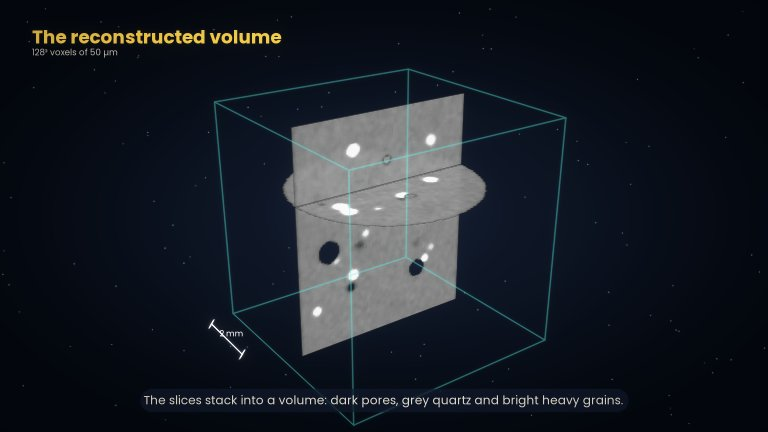

In [9]:
s3 = film.add_scene("Volume", 7.0, transition="crossfade", transition_duration=0.8)
cam = s3.camera
cam.set("target", (0, 0, 0)).set("offset", (0, 20)).set("distance", 150).set("elevation", 24)
cam.key("azimuth", 0, -70).key("azimuth", 7, -20, "in_out")
film.add("title", text="The reconstructed volume", subtitle=f"{N}³ voxels of {VOXEL_UM} µm", start=0.2)
UNIT_UM = N * VOXEL_UM / 44                                   # micrometres per scene unit (size 44)
vol = film.add("volume", name="Reconstruction", data="assets/reconstruction.npy", size=44, colormap="gray",
               vmin=0, vmax=0.75, show_y=False, clear_below=0.2, start=0.3)
vol.key("slice_z", 0.5, 0.08).key("slice_z", 6.5, 0.92, "in_out")
film.add("scalebar3d", origin=(-24, -26, -24), length=2000 / UNIT_UM, unit=f"{UNIT_UM:.4g} µm", start=0.8)
film.add("caption", text="The slices stack into a volume: dark pores, grey quartz and bright heavy grains.",
         style="box", start=0.8, end=6.8)
show(s3, 4.0)

### Scene 4: the segmentation

The grey-value histogram with the two Otsu thresholds, then the segmented slice laid over the reconstructed one,
and the porosity counting up to the measured value.

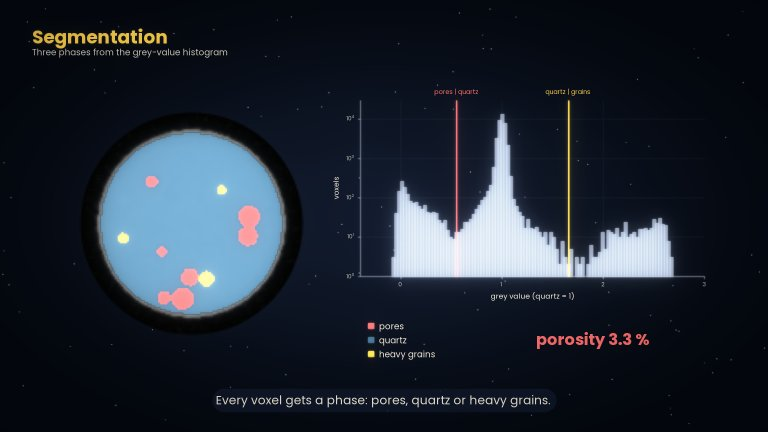

In [10]:
s4 = film.add_scene("Segmentation", 10.0, transition="wipe_left", transition_duration=0.8)
film.add("title", text="Segmentation", subtitle="Three phases from the grey-value histogram", start=0.2)
film.add("image", image="assets/slice_rec.png", position=(480, 560), width=560, mask="circle", start=0.3)
seg_img = film.add("image", image="assets/slice_seg.png", position=(480, 560), width=560, mask="circle", start=5.0)
seg_img.enter_duration = 1.2
ax = film.add("axes", name="Histogram", position=(900, 250), size=(860, 440), x_range=(-0.4, 3.0),
              y_range=(1, 30000), log_y=True, x_label="grey value (quartz = 1)", y_label="voxels",
              start=0.5)
film.add("histogram", axes=ax.id, data="assets/grey_values.csv", column="value", bins=120, normalize="count",
         color="gray", start=1.0)
film.add("guide", axes=ax.id, value=float(t_pore), color="pore", label="pores | quartz", start=2.8)
film.add("guide", axes=ax.id, value=float(t_grain), color="gold", label="quartz | grains", start=3.6)
film.add("legend", entries="pore | pores\nquartz | quartz\ngold | heavy grains", position=(920, 800), size=22,
         start=5.4)
poro = film.add("text", text="porosity {value:.1f} %", position=(1340, 820), size=40, color="pore",
                weight="bold", start=6.0)
poro.key("value", 6.2, 0.0).key("value", 8.5, 100 * porosity, "out")
film.add("caption", text="Otsu's method puts the thresholds where the classes separate best.", style="box",
         start=1.0, end=5.2)
film.add("caption", text="Every voxel gets a phase: pores, quartz or heavy grains.", style="box", start=5.4,
         end=9.8)
show(s4, 8.0)

### Scene 5: the pores in 3D

The pore and grain masks drawn as surfaces inside the outline of the core, with the measured numbers.

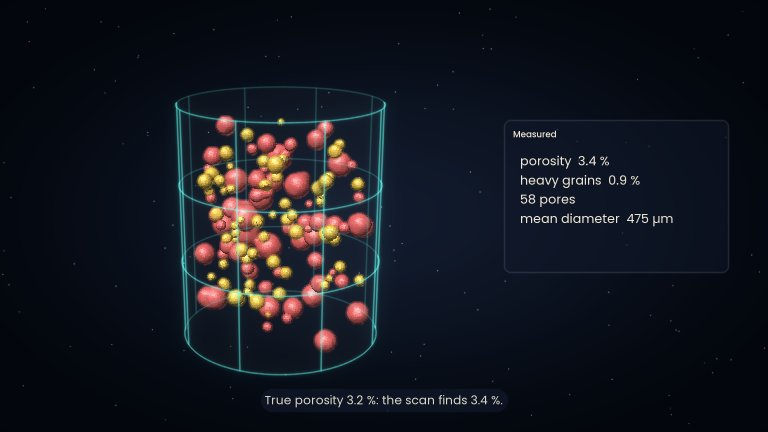

In [11]:
s5 = film.add_scene("Result", 8.0, transition="crossfade", transition_duration=0.8)
cam = s5.camera
cam.set("target", (0, 0, 0)).set("offset", (-260, 10)).set("distance", 150).set("elevation", 18)
cam.key("azimuth", 0, -40).key("azimuth", 8, 40, "in_out")
film.add("volume", name="Pores", data="assets/pores.npy", size=44, mode="isosurface", vmin=0, vmax=1,
         threshold=0.5, iso_color="pore", outline=False, start=0.3)
film.add("volume", name="Heavy grains", data="assets/grains.npy", size=44, mode="isosurface", vmin=0, vmax=1,
         threshold=0.5, iso_color="gold", outline=False, start=0.8)
film.add("cylinder", name="Core", radius=0.42 * 44, height=44, rings=4, lines=8, edge_color="teal",
         fill_opacity=0.02, start=0.3)
film.add("panel", title="Measured", position=(1260, 300), size=(560, 380), start=1.0)
film.add("text", text=(f"porosity  {100 * porosity:.1f} %\n"
                       f"heavy grains  {100 * grain_fraction:.1f} %\n"
                       f"{len(props)} pores\nmean diameter  {diam_um.mean():.0f} µm"),
         position=(1300, 380), size=32, line_spacing=1.5, start=1.4)
film.add("caption", text=f"True porosity {100 * true_porosity:.1f} %: the scan finds "
                         f"{100 * porosity:.1f} %.", style="box", start=1.5, end=7.8)
show(s5, 5.0)

## Check, preview and render

`film.validate()` lists problems (missing files, objects outside their scene). The preview plays in the notebook;
`render` writes the video (`scale=1` for full HD, `target="slides"` or `"conference"` for the presets).

no problems
5 scenes, 40.8 s: Measurement, Reconstruction, Volume, Segmentation, Result



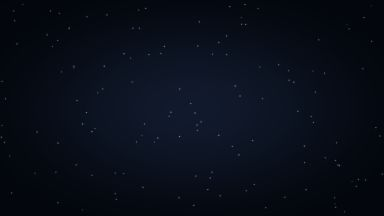

In [12]:
print(film.validate() or "no problems")
print(f"{len(film.scenes)} scenes, {film.duration:.1f} s:", ", ".join(sc.name for sc in film.scenes))
film.save()
film.preview(fps=3, scale=0.2)

In [13]:
video = film.render(FILM / "tomography.mp4", scale=0.5)
print(f"wrote {video} ({video.stat().st_size / 1e6:.1f} MB)")

wrote films/tomography/tomography.mp4 (6.3 MB)
